# QORC — zero-day novelty detection on a fixed photonic reservoir

**Scope.** This notebook covers the **novelty head only**. It is the zero-day
half of the two-head QORC system; the supervised head lives in
`qorc_supervised_multiclass.ipynb`. Both heads sit on top of the *same* fixed
quantum stack:

```
X (122 feat) --> scaler --> PCA(n_modes) --> tanh phase encode
                                                 |
                              precircuit -> phase dials -> reservoir     [FIXED]
                                                 |
                                          readout: C(m,p) probs
                                                 |
                        +------------------------+------------------------+
                        |                                                 |
                 NOVELTY HEAD                                   SUPERVISED HEAD
              (normal rows only)                              (attack labels)
              -- THIS NOTEBOOK --                             -- handled elsewhere --
```

The pre-circuit, encoding and reservoir are **identical** to the supervised
notebook. Nothing about the quantum stage is trained (`trainable_parameters=[]`).

---

## The core discipline: normal-only training

Every detector here is fitted on **normal traffic only**. It never sees a single
attack row of any kind during training.

That is what makes this a genuine zero-day evaluation, and it differs
fundamentally from the older `qorc_zeroday_analysis.ipynb`, which held out one
attack at a time while still training on the *other* attacks. Here there is
nothing to hold out — **no attack is ever in the training set**, so every one of
the 22 attack types in NSL-KDD is simultaneously "unseen". A single fitted
detector is scored against all of them.

This has a useful practical consequence: because the training set does not
depend on which attack we are scoring, the reservoir and the detector are fitted
**once per config** and then score all 22 attack types. The old notebook refit
everything per attack; that work was unnecessary here.

## What this sweep varies

Reservoir capacity — the `(photons, modes)` configuration that sets the readout
dimension — matching the supervised sweep so the two are directly comparable:

| config | photons | modes | readout dim = C(m,p) |
|---|---|---|---|
| `3p12m` | 3 | 12 | 220 |
| `3p20m` | 3 | 20 | 1140 |
| `3p24m` | 3 | 24 | 2024 |
| `4p24m` | 4 | 24 | 10626 |

`3p20m` is the config used in the original zero-day notebook, so it anchors the
comparison with existing results.

## Detectors — every one trained on normal only

| tag | input | dim | what it tests |
|---|---|---|---|
| `NOV_q` | reservoir readout | C(m,p) | the quantum arm |
| `NOV_dials` | PCA input to the reservoir | n_modes | **the tight control** |
| `NOV_raw` | full feature vector | 122 | classical reference |
| `IForest` | full feature vector | 122 | standard baseline (Isolation Forest) |

`NOV_dials` is the load-bearing control: it sees exactly the information that
entered the reservoir, through the same front-end. `gain = AUC(NOV_q) −
AUC(NOV_dials)` therefore isolates the reservoir's own contribution rather than
the preprocessing's.

## 1. Imports, configuration & run directory

In [1]:
import os, sys, math, json, time, platform, warnings, traceback
from pathlib import Path
from datetime import datetime

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.decomposition import PCA
from sklearn.model_selection import train_test_split
from sklearn.ensemble import IsolationForest
from sklearn.metrics import roc_auc_score, roc_curve, average_precision_score

import torch
import perceval as pcvl
import merlin as ML
try:
    MeasurementStrategy = ML.MeasurementStrategy
    ComputationSpace    = ML.ComputationSpace
except AttributeError:
    from merlin.measurement.strategies import MeasurementStrategy, ComputationSpace

warnings.filterwarnings("ignore")
plt.rcParams["figure.dpi"] = 110

# ---------------------------------------------------------------- settings
SEED      = 42
TEST_SIZE = 0.30          # fraction of NORMAL rows held out for scoring
DEVICE    = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Reservoir configs to sweep: (tag, n_photons, n_modes) -- same as the
# supervised notebook, so the two sweeps line up config for config.
CONFIGS = [
    ("3p12m", 3, 12),
    ("3p20m", 3, 20),
    ("3p24m", 3, 24),
    ("4p12m", 4, 12),
    ("4p20m", 4, 20),
    ("4p24m", 4, 24),
]

# Novelty detector: how many components describe the "normal" subspace.
N_NOV_COMPS = 32

# False-alarm budgets at which we report the detection rate. An operator does
# not get to choose a threshold after seeing the attacks, so AUC alone is not
# an operational number -- these are.
FA_BUDGETS = [0.001, 0.01, 0.05]

# Attack types with fewer rows than this are reported but excluded from
# headline aggregates: with n<20 an AUC is noise, not signal.
MIN_SUPPORT = 20

# Feature-matrix guard: refuse to build anything above this many GB.
MAX_FEATURE_GB = 6.0

np.random.seed(SEED)
torch.manual_seed(SEED)

# ---------------------------------------------------------------- run dir
RUN_ROOT = Path("qorc_nov_runs")
RUN_ROOT.mkdir(exist_ok=True)
RUN_ID   = datetime.now().strftime("%Y%m%d_%H%M%S")
RUN_DIR  = RUN_ROOT / RUN_ID
RUN_DIR.mkdir(exist_ok=True)
(RUN_DIR / "artifacts").mkdir(exist_ok=True)

LOG_PATH = RUN_DIR / "run.log"

def log(msg, level="INFO"):
    """Timestamped log to stdout AND to disk (flushed immediately).

    Everything important goes through here so a run that dies still leaves a
    complete, readable trace on disk.
    """
    line = f"{datetime.now().strftime('%H:%M:%S')} [{level:5s}] {msg}"
    print(line, flush=True)
    with open(LOG_PATH, "a", encoding="utf-8") as fh:
        fh.write(line + "\n")
        fh.flush()
        os.fsync(fh.fileno())

log(f"run id      : {RUN_ID}")
log(f"run dir     : {RUN_DIR.resolve()}")
log(f"device      : {DEVICE}"
    + (f" ({torch.cuda.get_device_name(0)})" if DEVICE.type == "cuda" else ""))
log(f"python      : {sys.version.split()[0]} | torch {torch.__version__}"
    f" | perceval {pcvl.__version__}")
log(f"configs     : {[c[0] for c in CONFIGS]}")
log(f"seed        : {SEED} (single seed -- see caveats in section 9)")
for tag, p, m in CONFIGS:
    dim = math.comb(m, p)
    log(f"  {tag:6s} -> readout dim {dim:6d} | full-data matrix "
        f"{125973*dim*4/1e9:.2f} GB")

21:06:40 [INFO ] run id      : 20260810_210640
21:06:40 [INFO ] run dir     : D:\Python\AI\Code\ReservoirComputing\QRC\team\qorc_nov_runs\20260810_210640
21:06:40 [INFO ] device      : cuda (NVIDIA GeForce RTX 2070 with Max-Q Design)
21:06:40 [INFO ] python      : 3.10.19 | torch 2.5.1+cu121 | perceval 1.2.1
21:06:40 [INFO ] configs     : ['3p12m', '3p20m', '3p24m', '4p12m', '4p20m', '4p24m']
21:06:40 [INFO ] seed        : 42 (single seed -- see caveats in section 9)
21:06:41 [INFO ]   3p12m  -> readout dim    220 | full-data matrix 0.11 GB
21:06:41 [INFO ]   3p20m  -> readout dim   1140 | full-data matrix 0.57 GB
21:06:41 [INFO ]   3p24m  -> readout dim   2024 | full-data matrix 1.02 GB
21:06:41 [INFO ]   4p12m  -> readout dim    495 | full-data matrix 0.25 GB
21:06:41 [INFO ]   4p20m  -> readout dim   4845 | full-data matrix 2.44 GB
21:06:41 [INFO ]   4p24m  -> readout dim  10626 | full-data matrix 5.35 GB


## 2. Data loading & the normal-only split

The split is the heart of the zero-day protocol, so it is worth being explicit:

* **Train** — 70% of `normal` rows. Nothing else. No attack of any kind.
* **Score-normal** — the remaining 30% of `normal` rows. These set the
  false-alarm rate and the detection threshold.
* **Score-attack** — **every** attack row in the dataset (58,630 rows across 22
  types). All of them are unseen by construction.

Because no attack participates in training, there is no leakage to reason about
and no per-attack refit to do.

In [2]:
CSV_CANDIDATES = [
    "NSL_KDD_labeled.csv",
    "../../NSL_KDD_labeled.csv",
    "data/NSL_KDD_labeled.csv",
    r"D:\Python\AI\Code\ReservoirComputing\NSL_KDD_labeled.csv",
]
csv_path = next((p for p in CSV_CANDIDATES if Path(p).exists()), None)
assert csv_path, "NSL_KDD_labeled.csv not found - add its path to CSV_CANDIDATES."
log(f"loading {csv_path}")

df = pd.read_csv(csv_path)
categorical_cols = ["protocol_type", "service", "flag"]
target_col       = "label"
numeric_cols     = [c for c in df.columns if c not in categorical_cols + [target_col]]

ohe   = OneHotEncoder(sparse_output=False, handle_unknown="ignore")
X_cat = ohe.fit_transform(df[categorical_cols]).astype(np.float32)
X_num = df[numeric_cols].to_numpy(dtype=np.float32)
X_all = np.concatenate([X_num, X_cat], axis=1)

raw_label   = df[target_col].to_numpy()
is_normal   = (raw_label == "normal")
attack_type = raw_label

# Every attack type in the file, most common first. Nothing is hand-picked:
# the detector never trains on attacks, so all of them are legitimately unseen.
ATTACKS = [a for a in pd.Series(raw_label[~is_normal]).value_counts().index]
ATTACK_N = {a: int((attack_type == a).sum()) for a in ATTACKS}
BIG_ATTACKS = [a for a in ATTACKS if ATTACK_N[a] >= MIN_SUPPORT]

log(f"data: {X_all.shape[0]:,} rows x {X_all.shape[1]} features")
log(f"      {is_normal.sum():,} normal / {(~is_normal).sum():,} attack "
    f"across {len(ATTACKS)} attack types")
log(f"      {len(BIG_ATTACKS)} types have >= {MIN_SUPPORT} rows (used for headline aggregates)")

# ---- the normal-only split ------------------------------------------------
normal_idx = np.where(is_normal)[0]
attack_idx = np.where(~is_normal)[0]
tr_idx, te_norm_idx = train_test_split(normal_idx, test_size=TEST_SIZE,
                                       random_state=SEED)

log(f"train        : {len(tr_idx):,} normal rows  (NO attacks -- zero-day protocol)")
log(f"score-normal : {len(te_norm_idx):,} normal rows")
log(f"score-attack : {len(attack_idx):,} attack rows (all {len(ATTACKS)} types)")

# Guard the protocol itself rather than trusting the code above.
assert is_normal[tr_idx].all(), "PROTOCOL VIOLATION: attack rows in the training set"
assert not set(tr_idx) & set(te_norm_idx), "train/score-normal overlap"
assert not set(tr_idx) & set(attack_idx),  "train/attack overlap"

pd.DataFrame({"n": [ATTACK_N[a] for a in ATTACKS],
              "used_in_aggregate": [a in BIG_ATTACKS for a in ATTACKS]},
             index=ATTACKS).T

21:06:41 [INFO ] loading ../../NSL_KDD_labeled.csv
21:06:43 [INFO ] data: 125,973 rows x 122 features
21:06:43 [INFO ]       67,343 normal / 58,630 attack across 22 attack types
21:06:43 [INFO ]       13 types have >= 20 rows (used for headline aggregates)
21:06:43 [INFO ] train        : 47,140 normal rows  (NO attacks -- zero-day protocol)
21:06:43 [INFO ] score-normal : 20,203 normal rows
21:06:43 [INFO ] score-attack : 58,630 attack rows (all 22 types)


,neptune,satan,ipsweep,portsweep,smurf,nmap,back,teardrop,warezclient,pod,...,warezmaster,land,imap,rootkit,loadmodule,ftp_write,multihop,phf,perl,spy
n,41214,3633,3599,2931,2646,1493,956,892,890,201,...,20,18,11,10,9,8,7,4,3,2
used_in_aggregate,True,True,True,True,True,True,True,True,True,True,...,True,False,False,False,False,False,False,False,False,False


## 3. Quantum stack — identical to the supervised notebook

`build_quantum_layer` is the same port, generalised over `(n_modes, n_photons)`:

* `precircuit` — a fixed random unitary
* `c_var` — one phase shifter per mode, driven by the encoded input (`px1..pxm`)
* `reservoir` — a copy of the pre-circuit unitary
* input state — `n_photons` photons spread evenly across the modes
* readout — unbunched photon-number probabilities, `C(n_modes, n_photons)` of them

`trainable_parameters=[]` — the reservoir never learns, under either head.

In [3]:
def build_quantum_layer(n_modes, n_photons, seed=SEED, device=DEVICE):
    """Build one photonic reservoir. Mirrors the supervised notebook exactly,
    generalised over (n_modes, n_photons)."""
    np.random.seed(seed)                    # perceval's random_unitary uses global numpy RNG
    U          = pcvl.Matrix.random_unitary(n_modes)
    precircuit = pcvl.Unitary(U)
    reservoir  = precircuit.copy()
    c_var = pcvl.Circuit(n_modes)
    for i in range(n_modes):
        c_var.add(i, pcvl.PS(pcvl.P(f"px{i+1}")))
    qorc_circuit = precircuit // c_var // reservoir

    step = (n_modes - 1) / (n_photons - 1) if n_photons > 1 else 0
    input_state = [0] * n_modes
    for k in range(n_photons):
        input_state[int(round(k * step))] = 1

    ql = ML.QuantumLayer(
        input_size=n_modes, circuit=qorc_circuit,
        trainable_parameters=[], input_parameters=["px"],
        input_state=input_state,
        measurement_strategy=MeasurementStrategy.probs(
            computation_space=ComputationSpace.UNBUNCHED),
        device=device)
    ql.eval()
    return ql


def quantum_features(ql, phases, batch=4096, device=DEVICE):
    """Push encoded phases through the reservoir, in batches, no grad."""
    outs = []
    with torch.no_grad():
        for i in range(0, len(phases), batch):
            xb = torch.tensor(phases[i:i+batch], dtype=torch.float32, device=device)
            outs.append(ql(xb).cpu().numpy())
    return np.concatenate(outs, 0).astype(np.float32)


def to_phase(Z, mu, sd):
    """Smooth tanh squash, no clipping, no wrap-around -> (0, pi).
    Identical to the supervised notebook."""
    return ((np.pi / 2) * (1 + np.tanh((Z - mu) / (3 * sd)))).astype(np.float32)

## 4. The novelty detector

Learns the shape of normal traffic and scores each row by how far it falls from
that shape. Two complementary terms:

* **Mahalanobis** — distance from the centre of normal, measured in units of
  normal's own spread. Catches traffic that is *inside* the normal subspace but
  at an implausible position.
* **Reconstruction error** — how much of the row falls *outside* the normal
  subspace altogether. Catches traffic whose shape normal traffic cannot express.

Neither term ever sees an attack, so nothing about an attack can be "learned".
That is the entire point: an attack type invented tomorrow is scored by exactly
the same rule as one in the file today.

The scaling statistics (`fit_stats`) are also computed on **normal-train only**
and applied unchanged to everything else. Fitting a scaler on the attack rows
would leak their distribution into the score, which is the subtle version of the
mistake this protocol exists to avoid.

In [4]:
class NoveltyDetector:
    """Learns the shape of normal traffic; scores each row by how far it falls
    from it. Mahalanobis (far from centre) + reconstruction error (outside the
    normal subspace). It never sees an attack, so nothing can be 'unseen'."""

    def __init__(self, k=N_NOV_COMPS):
        self.k = k

    def fit(self, Xn):
        self.mu = Xn.mean(0)
        Z = Xn - self.mu
        k = min(self.k, Z.shape[1], Z.shape[0] - 1)
        self.pca = PCA(n_components=k, svd_solver="randomized",
                       random_state=0).fit(Z)
        P = self.pca.transform(Z)
        self.sd = P.std(0) + 1e-8
        R = Z - self.pca.inverse_transform(P)
        r = np.sqrt((R ** 2).sum(1))
        self.rmu, self.rsd = r.mean(), r.std() + 1e-8
        return self

    def score(self, X, chunk=20000):
        """Higher = more anomalous. Chunked so a 10,626-dim score pass does not
        allocate a second full copy of the matrix (see the memory notes)."""
        out = np.empty(len(X), dtype=np.float64)
        for i in range(0, len(X), chunk):
            Z = X[i:i+chunk] - self.mu
            P = self.pca.transform(Z)
            maha = np.sqrt(((P / self.sd) ** 2).sum(1))
            R = Z - self.pca.inverse_transform(P)
            recon = (np.sqrt((R ** 2).sum(1)) - self.rmu) / self.rsd
            out[i:i+chunk] = maha + np.maximum(recon, 0)
        return out


def auc(s_normal, s_attack):
    """ROC-AUC of separating attack (positive) from normal (negative)."""
    y = np.r_[np.zeros(len(s_normal)), np.ones(len(s_attack))]
    return float(roc_auc_score(y, np.r_[s_normal, s_attack]))


def detection_at_fa(s_normal, s_attack, fa):
    """Detection rate when the threshold is set to allow `fa` false alarms.

    The threshold comes from the NORMAL scores only -- an operator can calibrate
    it without ever having seen the attack, which is what makes it deployable.
    """
    thr = np.quantile(s_normal, 1 - fa)
    return float((s_attack > thr).mean())


def fit_stats(Q):
    """Mean/std from normal-train only. Constant columns are left at zero."""
    mean = Q.mean(0, dtype=np.float64).astype(np.float32)
    std  = Q.std(0, dtype=np.float64).astype(np.float32)
    std[std < 1e-8] = 1.0
    return mean, std


def apply_stats_inplace(Q, mean, std):
    """Standardise IN PLACE. At 10,626 dims the obvious
    `scaler.transform(Q).astype(np.float32)` allocates two extra full copies and
    pushes RSS past 11 GB, which sends the machine into swap. Doing the
    arithmetic in place keeps the peak at one matrix."""
    Q -= mean
    Q /= std
    return Q

## 5. Per-config runner

One experiment = one reservoir config. Within it:

1. Fit the front-end (scaler + PCA) on **normal-train**.
2. Build the reservoir, push normal-train / normal-score / all-attacks through it.
3. Fit each of the four detectors on **normal-train** in its own representation.
4. Score normal-score and every attack type; record AUC, average precision, and
   detection rate at each false-alarm budget.

The attack scores are computed once over all 58,630 attack rows and then sliced
per type, rather than re-scored 22 times.

In [5]:
def run_config(tag, n_photons, n_modes, save_artifacts=True):
    """One reservoir config, end to end, over all attack types."""
    t_start = time.time()
    dim = math.comb(n_modes, n_photons)

    n_rows = len(tr_idx) + len(te_norm_idx) + len(attack_idx)
    gb = n_rows * dim * 4 / 1e9
    if gb > MAX_FEATURE_GB:
        raise MemoryError(f"{tag}: feature matrix would be {gb:.1f} GB "
                          f"(limit {MAX_FEATURE_GB} GB)")

    log(f"--- {tag}: readout dim {dim} Fock states, {gb:.2f} GB across {n_rows:,} rows ---")

    # ---- front-end: fitted on NORMAL-TRAIN only -----------------------------
    t0 = time.time()
    scaler = StandardScaler().fit(X_all[tr_idx])
    A = scaler.transform(X_all[tr_idx]).astype(np.float32)        # normal train
    B = scaler.transform(X_all[te_norm_idx]).astype(np.float32)   # normal score
    C = scaler.transform(X_all[attack_idx]).astype(np.float32)    # all attacks

    pca = PCA(n_components=n_modes, random_state=SEED).fit(A)
    Za, Zb, Zc = pca.transform(A), pca.transform(B), pca.transform(C)
    mu, sd = Za.mean(0), Za.std(0) + 1e-8
    log(f"  front-end fitted ({time.time()-t0:.1f}s), "
        f"PCA explains {pca.explained_variance_ratio_.sum():.1%} of variance")

    # ---- quantum features ---------------------------------------------------
    t0 = time.time()
    ql = build_quantum_layer(n_modes, n_photons)
    Qa = quantum_features(ql, to_phase(Za, mu, sd))
    Qb = quantum_features(ql, to_phase(Zb, mu, sd))
    Qc = quantum_features(ql, to_phase(Zc, mu, sd))
    t_quantum = time.time() - t0
    log(f"  Fock-state readout: {n_rows:,} rows x {Qa.shape[1]} in {t_quantum:.1f}s "
        f"({t_quantum/n_rows*1e3:.3f} ms/row)")

    # ---- standardise every representation on normal-train stats -------------
    q_mean, q_std = fit_stats(Qa)
    apply_stats_inplace(Qa, q_mean, q_std)
    apply_stats_inplace(Qb, q_mean, q_std)
    apply_stats_inplace(Qc, q_mean, q_std)

    Ra = Za.astype(np.float32, copy=True)
    Rb = Zb.astype(np.float32, copy=True)
    Rc = Zc.astype(np.float32, copy=True)
    r_mean, r_std = fit_stats(Ra)
    apply_stats_inplace(Ra, r_mean, r_std)
    apply_stats_inplace(Rb, r_mean, r_std)
    apply_stats_inplace(Rc, r_mean, r_std)

    # `raw` uses the 122-dim scaled features directly (A/B/C already scaled).

    rec = {"config": tag, "n_photons": n_photons, "n_modes": n_modes,
           "readout_dim": dim, "seed": SEED,
           "n_train_normal": len(tr_idx), "n_score_normal": len(te_norm_idx),
           "n_attack": len(attack_idx),
           "pca_explained_var": float(pca.explained_variance_ratio_.sum()),
           "t_quantum_s": t_quantum, "detectors": {}}

    # ---- detectors, all fitted on NORMAL-TRAIN only -------------------------
    reps = [("NOV_q",     Qa, Qb, Qc, dim),
            ("NOV_dials", Ra, Rb, Rc, n_modes),
            ("NOV_raw",   A,  B,  C,  A.shape[1])]

    atk_of_row = attack_type[attack_idx]

    for name, tr_rep, nb_rep, at_rep, d in reps:
        t0 = time.time()
        det = NoveltyDetector().fit(tr_rep)
        s_norm = det.score(nb_rep)
        s_atk  = det.score(at_rep)
        rec["detectors"][name] = summarise_scores(
            s_norm, s_atk, atk_of_row, d, time.time() - t0)
        log(f"  {name:10s} dim={d:5d} "
            f"AUC(all)={rec['detectors'][name]['auc_all']:.4f} "
            f"det@1%FA={rec['detectors'][name]['det_at_fa']['0.01']:.4f} "
            f"({rec['detectors'][name]['fit_score_time_s']:.1f}s)")
        if save_artifacts:
            np.savez_compressed(
                RUN_DIR / "artifacts" / f"scores_{tag}_{name}.npz",
                s_norm=s_norm.astype(np.float32),
                s_atk=s_atk.astype(np.float32))
        del det

    # Isolation Forest on the raw features -- the standard baseline.
    t0 = time.time()
    iso = IsolationForest(n_estimators=200, random_state=SEED, n_jobs=-1).fit(A)
    s_norm = -iso.score_samples(B)
    s_atk  = -iso.score_samples(C)
    rec["detectors"]["IForest"] = summarise_scores(
        s_norm, s_atk, atk_of_row, A.shape[1], time.time() - t0)
    log(f"  {'IForest':10s} dim={A.shape[1]:5d} "
        f"AUC(all)={rec['detectors']['IForest']['auc_all']:.4f} "
        f"det@1%FA={rec['detectors']['IForest']['det_at_fa']['0.01']:.4f} "
        f"({rec['detectors']['IForest']['fit_score_time_s']:.1f}s)")
    if save_artifacts:
        np.savez_compressed(RUN_DIR / "artifacts" / f"scores_{tag}_IForest.npz",
                            s_norm=s_norm.astype(np.float32),
                            s_atk=s_atk.astype(np.float32))
    del iso

    # ---- headline gain: quantum vs its own input ----------------------------
    q, dl = rec["detectors"]["NOV_q"], rec["detectors"]["NOV_dials"]
    rec["gain_auc_vs_dials"] = q["auc_all"] - dl["auc_all"]
    rec["gain_auc_vs_raw"]   = q["auc_all"] - rec["detectors"]["NOV_raw"]["auc_all"]
    rec["total_time_s"]      = time.time() - t_start
    log(f"  GAIN NOV_q - NOV_dials: AUC {rec['gain_auc_vs_dials']:+.4f} | "
        f"vs raw {rec['gain_auc_vs_raw']:+.4f} "
        f"(total {rec['total_time_s']:.1f}s)")

    del Qa, Qb, Qc, Ra, Rb, Rc, A, B, C, Za, Zb, Zc, ql
    if DEVICE.type == "cuda":
        torch.cuda.empty_cache()
    return rec


def summarise_scores(s_norm, s_atk, atk_of_row, input_dim, elapsed):
    """Metric bundle for one detector: overall + per attack type."""
    out = {
        "input_dim": int(input_dim),
        "fit_score_time_s": float(elapsed),
        "auc_all": auc(s_norm, s_atk),
        "ap_all": float(average_precision_score(
            np.r_[np.zeros(len(s_norm)), np.ones(len(s_atk))],
            np.r_[s_norm, s_atk])),
        "det_at_fa": {str(fa): detection_at_fa(s_norm, s_atk, fa)
                      for fa in FA_BUDGETS},
        "normal_score_mean": float(s_norm.mean()),
        "per_attack": {},
    }
    for a in ATTACKS:
        sel = (atk_of_row == a)
        sa = s_atk[sel]
        out["per_attack"][a] = {
            "n": int(sel.sum()),
            "auc": auc(s_norm, sa),
            "det_at_fa": {str(fa): detection_at_fa(s_norm, sa, fa)
                          for fa in FA_BUDGETS},
            "score_mean": float(sa.mean()),
        }
    # Macro average over attack types big enough to mean anything -- this is
    # the number to quote, because the micro AUC is dominated by neptune
    # (41,214 of the 58,630 attack rows).
    big = [out["per_attack"][a]["auc"] for a in BIG_ATTACKS]
    out["auc_macro_big"] = float(np.mean(big)) if big else None
    return out

## 6. Smoke test — validate everything before the full run

Runs the entire pipeline on a subsample with the smallest config, plus
assertions on the pieces that are easy to get silently wrong — above all, the
**normal-only training protocol**, which is the one thing that would invalidate
every number in this notebook if it broke.

**Do not start the full run until this cell prints `SMOKE TEST PASSED`.**

In [6]:
def smoke_test():
    global tr_idx, te_norm_idx, attack_idx
    ok, checks = True, []

    def check(name, cond, detail=""):
        nonlocal ok
        ok &= bool(cond)
        checks.append((name, bool(cond), detail))
        log(f"  [{'PASS' if cond else 'FAIL'}] {name} {detail}",
            "INFO" if cond else "ERROR")

    log("=== SMOKE TEST ===")

    # 1. reservoir shape & determinism
    ql = build_quantum_layer(12, 3, seed=SEED)
    x  = np.random.uniform(0, np.pi, size=(64, 12)).astype(np.float32)
    f1 = quantum_features(ql, x)
    check("readout dim == C(12,3)", f1.shape[1] == math.comb(12, 3),
          f"got {f1.shape[1]}, expected {math.comb(12,3)}")
    check("probabilities in [0,1]", (f1 >= -1e-6).all() and (f1 <= 1+1e-6).all(),
          f"range [{f1.min():.3e}, {f1.max():.3e}]")
    check("rows sum to ~1", np.allclose(f1.sum(1), 1.0, atol=1e-3),
          f"sums in [{f1.sum(1).min():.4f}, {f1.sum(1).max():.4f}]")
    f2 = quantum_features(build_quantum_layer(12, 3, seed=SEED), x)
    check("reservoir reproducible for a fixed seed", np.allclose(f1, f2, atol=1e-6))
    f3 = quantum_features(build_quantum_layer(12, 3, seed=SEED + 1), x)
    check("different seed -> different reservoir", not np.allclose(f1, f3, atol=1e-6))

    # 2. every config builds and gives the right dim
    for tag, p, m in CONFIGS:
        try:
            q = build_quantum_layer(m, p)
            d = quantum_features(q, np.random.uniform(0, np.pi, (8, m)).astype(np.float32))
            check(f"config {tag} builds, dim {math.comb(m,p)}",
                  d.shape[1] == math.comb(m, p), f"got {d.shape[1]}")
            del q, d
        except Exception as e:
            check(f"config {tag} builds", False, f"{type(e).__name__}: {e}")
    if DEVICE.type == "cuda":
        torch.cuda.empty_cache()

    # 3. encoding is bounded and order-preserving
    Z  = np.linspace(-50, 50, 500).reshape(-1, 1)
    ph = to_phase(Z, np.array([0.0]), np.array([1.0]))
    check("phase bounded in [0, pi]", (ph >= 0).all() and (ph <= np.pi).all(),
          f"range [{ph.min():.4f}, {ph.max():.4f}]")
    check("phase monotonic (order preserved)", (np.diff(ph.ravel()) >= 0).all())
    Zc = np.linspace(-12, 12, 500).reshape(-1, 1)
    phc = to_phase(Zc, np.array([0.0]), np.array([1.0]))
    check("phase strictly increasing over +/-4 sd (no clipping on real data)",
          (np.diff(phc.ravel()) > 0).all())

    # 4. THE PROTOCOL -- the check that matters most in this notebook
    check("training set is 100% normal (zero-day protocol)",
          bool(is_normal[tr_idx].all()),
          f"{int((~is_normal[tr_idx]).sum())} attack rows found in train")
    check("no train/score-normal overlap", not (set(tr_idx) & set(te_norm_idx)))
    check("no train/attack overlap", not (set(tr_idx) & set(attack_idx)))
    check("all attack rows are scored",
          len(attack_idx) == int((~is_normal).sum()),
          f"{len(attack_idx):,} of {int((~is_normal).sum()):,}")
    check("every attack type is represented",
          len(ATTACKS) == df[target_col].nunique() - 1,
          f"{len(ATTACKS)} types")

    # 5. the detector separates a trivially anomalous toy problem
    rng = np.random.default_rng(0)
    Xn  = rng.normal(0, 1, (2000, 10)).astype(np.float32)
    Xa  = rng.normal(6, 1, (200, 10)).astype(np.float32)
    d   = NoveltyDetector(k=5).fit(Xn)
    a   = auc(d.score(Xn), d.score(Xa))
    check("detector solves a separable toy problem", a > 0.99, f"AUC={a:.4f}")
    # a detector fitted on normal must NOT flag held-out normal
    Xn2 = rng.normal(0, 1, (500, 10)).astype(np.float32)
    a2  = auc(d.score(Xn), d.score(Xn2))
    check("detector does not flag held-out normal (AUC ~ 0.5)",
          0.4 < a2 < 0.6, f"AUC={a2:.4f}")

    # 6. chunked scoring == unchunked
    s_chunk = d.score(Xa, chunk=32)
    s_whole = d.score(Xa, chunk=10**9)
    check("chunked scoring matches unchunked",
          np.allclose(s_chunk, s_whole, atol=1e-9),
          f"max diff {np.abs(s_chunk-s_whole).max():.2e}")

    # 7. detection_at_fa respects its budget on normal data
    fa_emp = detection_at_fa(d.score(Xn), d.score(Xn2), 0.05)
    check("false-alarm budget calibrates on normal (~0.05)",
          0.01 < fa_emp < 0.12, f"empirical {fa_emp:.4f}")

    # 8. full pipeline on a subsample
    full = (tr_idx, te_norm_idx, attack_idx)
    try:
        rng2 = np.random.default_rng(SEED)
        tr_idx     = rng2.choice(full[0], 4000, replace=False)
        te_norm_idx = rng2.choice(full[1], 2000, replace=False)
        attack_idx = rng2.choice(full[2], 4000, replace=False)
        r = run_config("3p12m", 3, 12, save_artifacts=False)
        check("end-to-end config returns metrics",
              0 <= r["detectors"]["NOV_q"]["auc_all"] <= 1,
              f"AUC={r['detectors']['NOV_q']['auc_all']:.3f}")
        check("result record is JSON-serialisable", bool(json.dumps(r)))
        check("per-attack breakdown present",
              len(r["detectors"]["NOV_q"]["per_attack"]) == len(ATTACKS))
    except Exception as e:
        check("end-to-end config", False, f"{type(e).__name__}: {e}")
        traceback.print_exc()
    finally:
        tr_idx, te_norm_idx, attack_idx = full

    # 9. enough disk
    import shutil
    free_gb = shutil.disk_usage(RUN_DIR).free / 1e9
    check("at least 1 GB free disk", free_gb > 1.0, f"{free_gb:.1f} GB free")

    n_fail = sum(1 for _, c, _ in checks if not c)
    log("=" * 60)
    if ok:
        log(f"SMOKE TEST PASSED ({len(checks)} checks) - safe to start the full run")
    else:
        log(f"SMOKE TEST FAILED - {n_fail}/{len(checks)} checks failed. "
            f"Fix before running.", "ERROR")
    log("=" * 60)
    return ok

SMOKE_OK = smoke_test()

21:06:43 [INFO ] === SMOKE TEST ===
21:06:45 [INFO ]   [PASS] readout dim == C(12,3) got 220, expected 220
21:06:45 [INFO ]   [PASS] probabilities in [0,1] range [3.312e-08, 6.762e-02]
21:06:45 [INFO ]   [PASS] rows sum to ~1 sums in [1.0000, 1.0000]
21:06:45 [INFO ]   [PASS] reservoir reproducible for a fixed seed 
21:06:45 [INFO ]   [PASS] different seed -> different reservoir 
21:06:46 [INFO ]   [PASS] config 3p12m builds, dim 220 got 220
21:06:46 [INFO ]   [PASS] config 3p20m builds, dim 1140 got 1140
21:06:46 [INFO ]   [PASS] config 3p24m builds, dim 2024 got 2024
21:06:46 [INFO ]   [PASS] config 4p12m builds, dim 495 got 495
21:06:46 [INFO ]   [PASS] config 4p20m builds, dim 4845 got 4845
21:06:47 [INFO ]   [PASS] config 4p24m builds, dim 10626 got 10626
21:06:47 [INFO ]   [PASS] phase bounded in [0, pi] range [0.0000, 3.1416]
21:06:47 [INFO ]   [PASS] phase monotonic (order preserved) 
21:06:47 [INFO ]   [PASS] phase strictly increasing over +/-4 sd (no clipping on real data) 
2

## 7. The sweep — crash-safe, resumable

Every config is checkpointed to `results.jsonl` **the moment it finishes**, one
JSON object per line, flushed and `fsync`-ed. If the machine dies, rerunning
this cell skips what is already recorded and resumes where it stopped.

A failing config is logged with its traceback and the sweep continues.

In [7]:
RESULTS_PATH = RUN_DIR / "results.jsonl"

def find_resumable():
    """Newest run dir that already has partial results."""
    for d in sorted(RUN_ROOT.iterdir(), reverse=True):
        if d.is_dir() and (d / "results.jsonl").exists() and d != RUN_DIR:
            return d
    return None

RESUME_FROM = None          # <- set to a Path to resume a previous run, or leave None
if RESUME_FROM is not None:
    RESULTS_PATH = Path(RESUME_FROM) / "results.jsonl"
    log(f"RESUMING into {RESULTS_PATH}", "WARN")

def load_done():
    done = {}
    if RESULTS_PATH.exists():
        with open(RESULTS_PATH, encoding="utf-8") as fh:
            for line in fh:
                line = line.strip()
                if not line:
                    continue
                try:
                    r = json.loads(line)
                    done[r["config"]] = r
                except json.JSONDecodeError:
                    log("skipping a corrupt results line", "WARN")
    return done

def append_result(rec):
    with open(RESULTS_PATH, "a", encoding="utf-8") as fh:
        fh.write(json.dumps(rec) + "\n")
        fh.flush()
        os.fsync(fh.fileno())

if not SMOKE_OK:
    raise RuntimeError("Smoke test failed - refusing to start the sweep. "
                       "Fix the failures reported above first.")

done = load_done()
todo = [c for c in CONFIGS if c[0] not in done]

log("=" * 70)
log(f"SWEEP: {len(CONFIGS)} configs, {len(done)} already done, {len(todo)} to run")
log(f"results -> {RESULTS_PATH}")
log("=" * 70)

t_sweep = time.time()
for i, (tag, p, m) in enumerate(todo, 1):
    log(f"[{i}/{len(todo)}] {tag}   (elapsed {(time.time()-t_sweep)/60:.1f} min)")
    try:
        rec = run_config(tag, p, m)
        rec["run_id"], rec["timestamp"] = RUN_ID, datetime.now().isoformat()
        append_result(rec)
        done[tag] = rec
        log(f"[{i}/{len(todo)}] saved.")
    except Exception as e:
        log(f"[{i}/{len(todo)}] {tag} FAILED: {type(e).__name__}: {e}", "ERROR")
        with open(RUN_DIR / "errors.log", "a", encoding="utf-8") as fh:
            fh.write(f"\n=== {tag} @ {datetime.now().isoformat()} ===\n")
            traceback.print_exc(file=fh)
            fh.flush()
        traceback.print_exc()
        if DEVICE.type == "cuda":
            torch.cuda.empty_cache()

log("=" * 70)
log(f"SWEEP COMPLETE in {(time.time()-t_sweep)/60:.1f} min - "
    f"{len(done)}/{len(CONFIGS)} configs on disk")
log("=" * 70)

21:06:49 [INFO ] ======================================================================
21:06:49 [INFO ] SWEEP: 6 configs, 0 already done, 6 to run
21:06:49 [INFO ] results -> qorc_nov_runs\20260810_210640\results.jsonl
21:06:49 [INFO ] ======================================================================
21:06:49 [INFO ] [1/6] 3p12m   (elapsed 0.0 min)
21:06:49 [INFO ] --- 3p12m: readout dim 220 Fock states, 0.11 GB across 125,973 rows ---
21:06:50 [INFO ]   front-end fitted (0.4s), PCA explains 48.1% of variance
21:06:50 [INFO ]   Fock-state readout: 125,973 rows x 220 in 0.6s (0.005 ms/row)
21:06:52 [INFO ]   NOV_q      dim=  220 AUC(all)=0.9698 det@1%FA=0.2327 (1.1s)
21:06:52 [INFO ]   NOV_dials  dim=   12 AUC(all)=0.9581 det@1%FA=0.6335 (0.1s)
21:06:53 [INFO ]   NOV_raw    dim=  122 AUC(all)=0.9616 det@1%FA=0.2999 (0.7s)
21:06:56 [INFO ]   IForest    dim=  122 AUC(all)=0.9798 det@1%FA=0.7975 (2.4s)
21:06:56 [INFO ]   GAIN NOV_q - NOV_dials: AUC +0.0116 | vs raw +0.0082 (total 6.8

---
# Part II — Result investigation

Everything below reads from `results.jsonl`, so it can be run in a **fresh
kernel** without recomputing anything. Point `INSPECT_PATH` at the run you want.

## 8. Load results

In [8]:
# Analyse the current run by default; set explicitly to inspect an older one.
INSPECT_PATH = RESULTS_PATH        # e.g. Path("qorc_nov_runs/20260726_120000/results.jsonl")

rows = []
with open(INSPECT_PATH, encoding="utf-8") as fh:
    for line in fh:
        if line.strip():
            rows.append(json.loads(line))
print(f"loaded {len(rows)} configs from {INSPECT_PATH}")

CONFIG_ORDER = [c[0] for c in CONFIGS]
DETECTORS    = ["NOV_q", "NOV_dials", "NOV_raw", "IForest"]

# Shared handles used by every analysis cell below.
by_cfg = {r["config"]: r for r in rows}
cfgs   = [c for c in CONFIG_ORDER if c in by_cfg]
art    = Path(INSPECT_PATH).parent / "artifacts"

flat = []
for r in rows:
    for det in DETECTORS:
        if det not in r["detectors"]:
            continue
        h = r["detectors"][det]
        flat.append({
            "config": r["config"], "detector": det,
            "readout_dim": r["readout_dim"], "input_dim": h["input_dim"],
            "n_photons": r["n_photons"], "n_modes": r["n_modes"],
            "auc_all": h["auc_all"], "auc_macro_big": h["auc_macro_big"],
            "ap_all": h["ap_all"],
            **{f"det@{fa}": h["det_at_fa"][str(fa)] for fa in FA_BUDGETS},
            "t_quantum_s": r["t_quantum_s"],
            "fit_score_time_s": h["fit_score_time_s"],
        })
D = pd.DataFrame(flat)
D["config"] = pd.Categorical(D["config"], CONFIG_ORDER, ordered=True)
D = D.sort_values(["config", "detector"]).reset_index(drop=True)
D.round(4)

loaded 6 configs from qorc_nov_runs\20260810_210640\results.jsonl


,config,detector,readout_dim,input_dim,n_photons,n_modes,auc_all,auc_macro_big,ap_all,det@0.001,det@0.01,det@0.05,t_quantum_s,fit_score_time_s
0,3p12m,IForest,220,122,3,12,0.9798,0.9074,0.9923,0.4060,0.7975,0.8863,0.6005,2.4258
1,3p12m,NOV_dials,220,12,3,12,0.9581,0.8653,0.9790,0.0006,0.6335,0.8104,0.6005,0.1103
2,3p12m,NOV_q,220,220,3,12,0.9698,0.9120,0.9849,0.0504,0.2327,0.9191,0.6005,1.1005
3,3p12m,NOV_raw,220,122,3,12,0.9616,0.8985,0.9800,0.0229,0.2999,0.8169,0.6005,0.7353
4,3p20m,IForest,1140,122,3,20,0.9798,0.9074,0.9923,0.4060,0.7975,0.8863,1.9067,2.3108
5,3p20m,NOV_dials,1140,20,3,20,0.9640,0.8939,0.9831,0.0064,0.6224,0.8238,1.9067,0.1757
6,3p20m,NOV_q,1140,1140,3,20,0.9520,0.9067,0.9689,0.0018,0.0649,0.6364,1.9067,3.8271
7,3p20m,NOV_raw,1140,122,3,20,0.9616,0.8985,0.9800,0.0229,0.2999,0.8169,1.9067,0.5292
8,3p24m,IForest,2024,122,3,24,0.9798,0.9074,0.9923,0.4060,0.7975,0.8863,2.9203,2.0674
9,3p24m,NOV_dials,2024,24,3,24,0.9614,0.8946,0.9804,0.0136,0.4036,0.8172,2.9203,0.2205


### 8.1 Headline table — quantum vs its controls, per config

`auc_all` pools every attack row, so it is dominated by `neptune` (41,214 of
58,630 rows). `auc_macro_big` averages over attack *types* with at least
`MIN_SUPPORT` rows and is the fairer headline: it does not let one huge attack
family speak for the whole threat landscape.

In [9]:
piv = D.pivot_table(index="config", columns="detector",
                    values=["auc_all", "auc_macro_big"], observed=True)
piv = piv.reindex([c for c in CONFIG_ORDER if c in piv.index])

out = pd.DataFrame(index=piv.index)
out["readout_dim"] = D.drop_duplicates("config").set_index("config")["readout_dim"].reindex(out.index)
for met in ("auc_all", "auc_macro_big"):
    for det in DETECTORS:
        if (met, det) in piv.columns:
            out[f"{met[4:]}_{det}"] = piv[(met, det)]
    if (met, "NOV_q") in piv.columns and (met, "NOV_dials") in piv.columns:
        out[f"{met[4:]}_GAIN_vs_dials"] = piv[(met, "NOV_q")] - piv[(met, "NOV_dials")]

print("===== AUC: pooled (all) and macro over attack types with n >= "
      f"{MIN_SUPPORT} (macro_big) =====")
print(out.round(4).to_string())

===== AUC: pooled (all) and macro over attack types with n >= 20 (macro_big) =====
        readout_dim  all_NOV_q  all_NOV_dials  all_NOV_raw  all_IForest  all_GAIN_vs_dials  macro_big_NOV_q  macro_big_NOV_dials  macro_big_NOV_raw  macro_big_IForest  macro_big_GAIN_vs_dials
config                                                                                                                                                                                         
3p12m           220     0.9698         0.9581       0.9616       0.9798             0.0116           0.9120               0.8653             0.8985             0.9074                   0.0467
3p20m          1140     0.9520         0.9640       0.9616       0.9798            -0.0120           0.9067               0.8939             0.8985             0.9074                   0.0128
3p24m          2024     0.9503         0.9614       0.9616       0.9798            -0.0112           0.9044               0.8946             0.8985  

### 8.2 Does more reservoir capacity help the novelty head?

The core question this sweep exists to answer. If the quantum curve rises with
readout dimension while `NOV_dials` stays flat, the reservoir is contributing
something the PCA front-end alone does not.

Note the asymmetry with the supervised head: a bigger readout gives a *linear
classifier* more room, but a novelty detector at higher dimension faces the
curse of dimensionality — Mahalanobis distance concentrates, and every point
starts to look equidistant. There is no guarantee the curve rises.

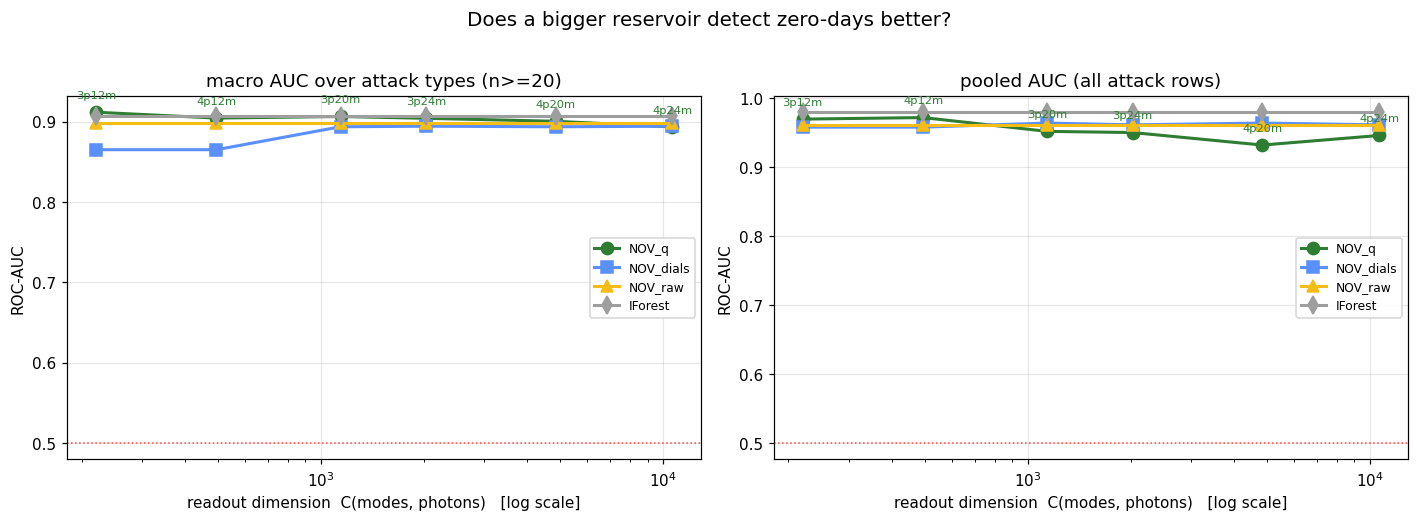

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.6))
for ax, met, title in [(axes[0], "auc_macro_big", f"macro AUC over attack types (n>={MIN_SUPPORT})"),
                       (axes[1], "auc_all", "pooled AUC (all attack rows)")]:
    for det, color, mk in [("NOV_q", "#2E7D32", "o"), ("NOV_dials", "#5B8FF9", "s"),
                           ("NOV_raw", "#F6BD16", "^"), ("IForest", "#9E9E9E", "d")]:
        s = D[D["detector"] == det].sort_values("readout_dim")
        if not len(s) or s[met].isna().all():
            continue
        ax.plot(s["readout_dim"], s[met], marker=mk, color=color,
                label=det, lw=2, ms=8)
    s = D[D["detector"] == "NOV_q"].sort_values("readout_dim")
    for _, r in s.iterrows():
        ax.annotate(r["config"], (r["readout_dim"], r[met]),
                    textcoords="offset points", xytext=(0, 9),
                    ha="center", fontsize=7.5, color="#2E7D32")
    ax.set_xscale("log")
    ax.axhline(0.5, color="red", ls=":", lw=1, alpha=0.7)
    ax.set_xlabel("readout dimension  C(modes, photons)   [log scale]")
    ax.set_ylabel("ROC-AUC")
    ax.set_title(title)
    ax.grid(alpha=0.3); ax.legend(fontsize=8)
fig.suptitle("Does a bigger reservoir detect zero-days better?", y=1.02, fontsize=13)
plt.tight_layout(); plt.show()

### 8.3 Quantum gain per config — reservoir minus its own input

`NOV_dials` is the tight control: same front-end, same detector, but without the
reservoir. A positive bar means the photonic layer added something.

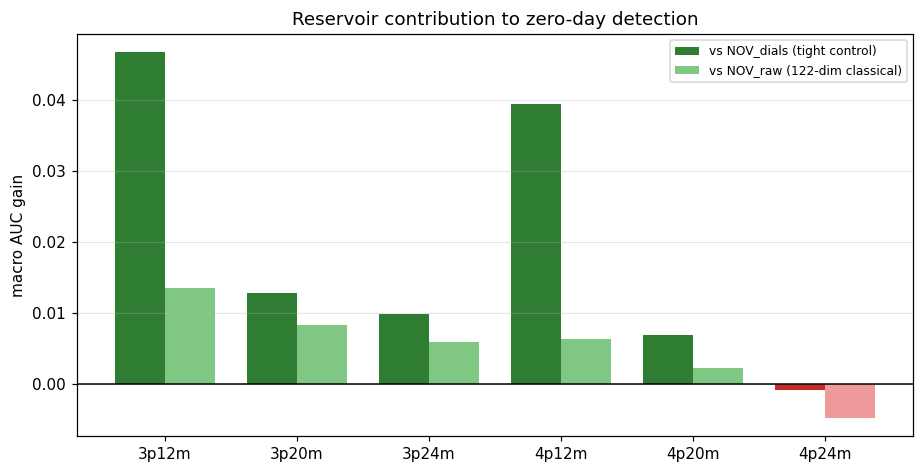

In [11]:
g = []
for cfg in cfgs:
    s = D[D["config"] == cfg]
    q = s[s["detector"] == "NOV_q"]
    d = s[s["detector"] == "NOV_dials"]
    rw = s[s["detector"] == "NOV_raw"]
    if len(q) and len(d) and len(rw):
        g.append((cfg,
                  q.iloc[0]["auc_macro_big"] - d.iloc[0]["auc_macro_big"],
                  q.iloc[0]["auc_macro_big"] - rw.iloc[0]["auc_macro_big"]))

if g:
    fig, ax = plt.subplots(figsize=(8.5, 4.4))
    x = np.arange(len(g)); w = 0.38
    ax.bar(x - w/2, [v[1] for v in g], w, label="vs NOV_dials (tight control)",
           color=["#2E7D32" if v[1] > 0 else "#C62828" for v in g])
    ax.bar(x + w/2, [v[2] for v in g], w, label="vs NOV_raw (122-dim classical)",
           color=["#81C784" if v[2] > 0 else "#EF9A9A" for v in g])
    ax.axhline(0, color="k", lw=1)
    ax.set_xticks(x); ax.set_xticklabels([v[0] for v in g])
    ax.set_ylabel("macro AUC gain")
    ax.set_title("Reservoir contribution to zero-day detection")
    ax.grid(axis="y", alpha=0.3); ax.legend(fontsize=8)
    plt.tight_layout(); plt.show()
else:
    print("not enough results to plot gains yet")

### 8.4 Per-attack AUC — which zero-days are actually catchable?

The aggregate hides everything interesting. Some attack types are trivially
anomalous (a flood looks nothing like normal traffic); others are close mimics
of normal behaviour and no novelty detector will separate them. This table is
where the honest limitations live.

Rows are ordered by frequency. Types below the support threshold are shown but
greyed out of the aggregates — with `n=2` an AUC is one row's luck.

In [12]:
DET_FOR_TABLE = "NOV_q"

tbl = {}
for cfg in cfgs:
    pa = by_cfg[cfg]["detectors"][DET_FOR_TABLE]["per_attack"]
    tbl[cfg] = {a: pa[a]["auc"] for a in ATTACKS if a in pa}
T = pd.DataFrame(tbl)
T.insert(0, "n", [ATTACK_N[a] for a in T.index])
T.insert(1, "aggregated", [a in BIG_ATTACKS for a in T.index])
print(f"===== per-attack AUC - {DET_FOR_TABLE} (normal-only training) =====")
print(T.round(3).to_string())

# Same table, but the gain over the tight control
tbl2 = {}
for cfg in cfgs:
    q  = by_cfg[cfg]["detectors"]["NOV_q"]["per_attack"]
    dl = by_cfg[cfg]["detectors"]["NOV_dials"]["per_attack"]
    tbl2[cfg] = {a: q[a]["auc"] - dl[a]["auc"] for a in ATTACKS if a in q}
T2 = pd.DataFrame(tbl2)
T2.insert(0, "n", [ATTACK_N[a] for a in T2.index])
print(f"\n===== per-attack AUC GAIN (NOV_q - NOV_dials) =====")
print(T2.round(3).to_string())

===== per-attack AUC - NOV_q (normal-only training) =====
                     n  aggregated  3p12m  3p20m  3p24m  4p12m  4p20m  4p24m
neptune          41214        True  0.987  0.963  0.963  0.995  0.937  0.961
satan             3633        True  0.948  0.942  0.931  0.933  0.927  0.933
ipsweep           3599        True  0.972  0.981  0.966  0.936  0.978  0.950
portsweep         2931        True  0.997  0.978  0.977  0.990  0.979  0.967
smurf             2646        True  0.976  0.986  0.974  0.987  0.967  0.972
nmap              1493        True  0.932  0.961  0.955  0.920  0.961  0.957
back               956        True  0.495  0.377  0.382  0.506  0.379  0.347
teardrop           892        True  0.843  0.895  0.903  0.830  0.884  0.896
warezclient        890        True  0.843  0.839  0.856  0.822  0.845  0.826
pod                201        True  0.969  0.983  0.981  0.952  0.986  0.985
guess_passwd        53        True  0.994  0.997  0.990  0.998  0.994  0.977
buffer_overflow   

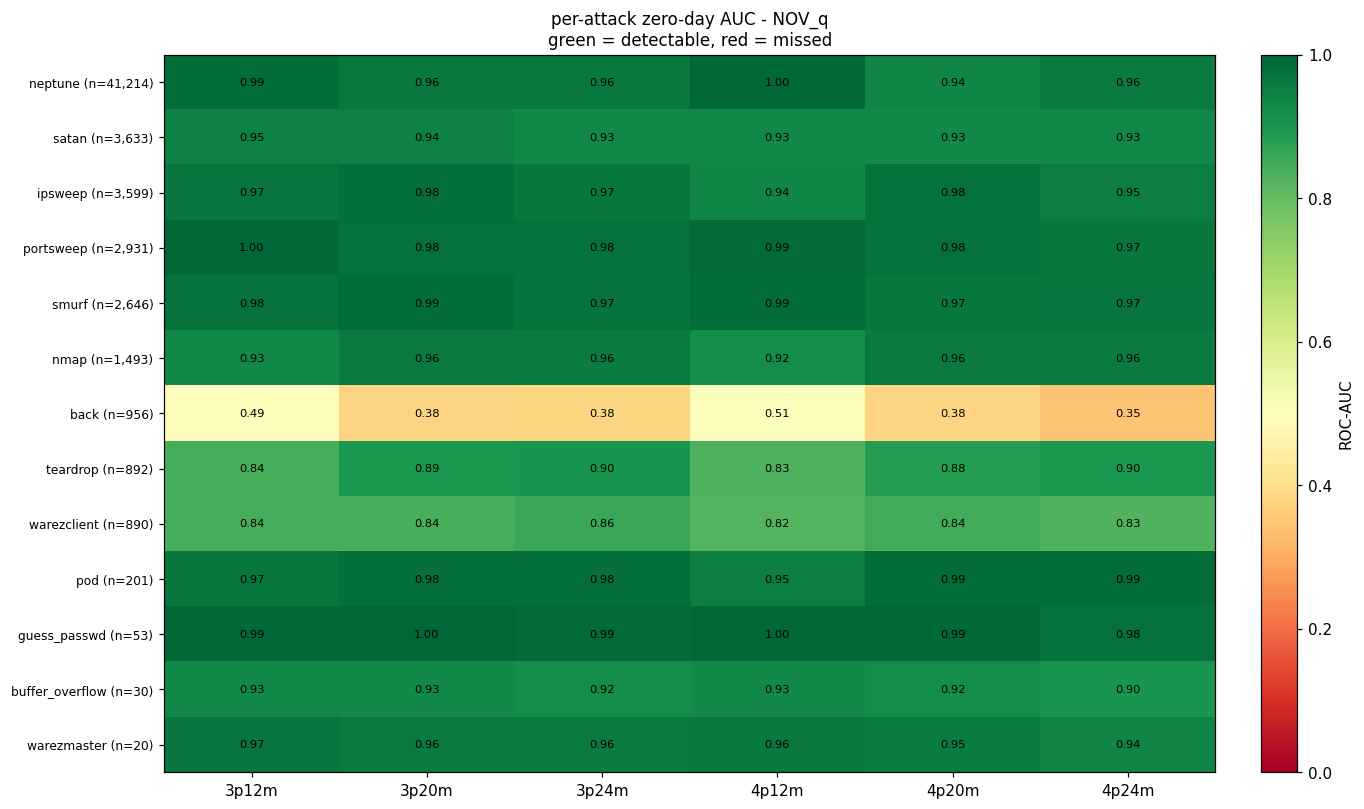

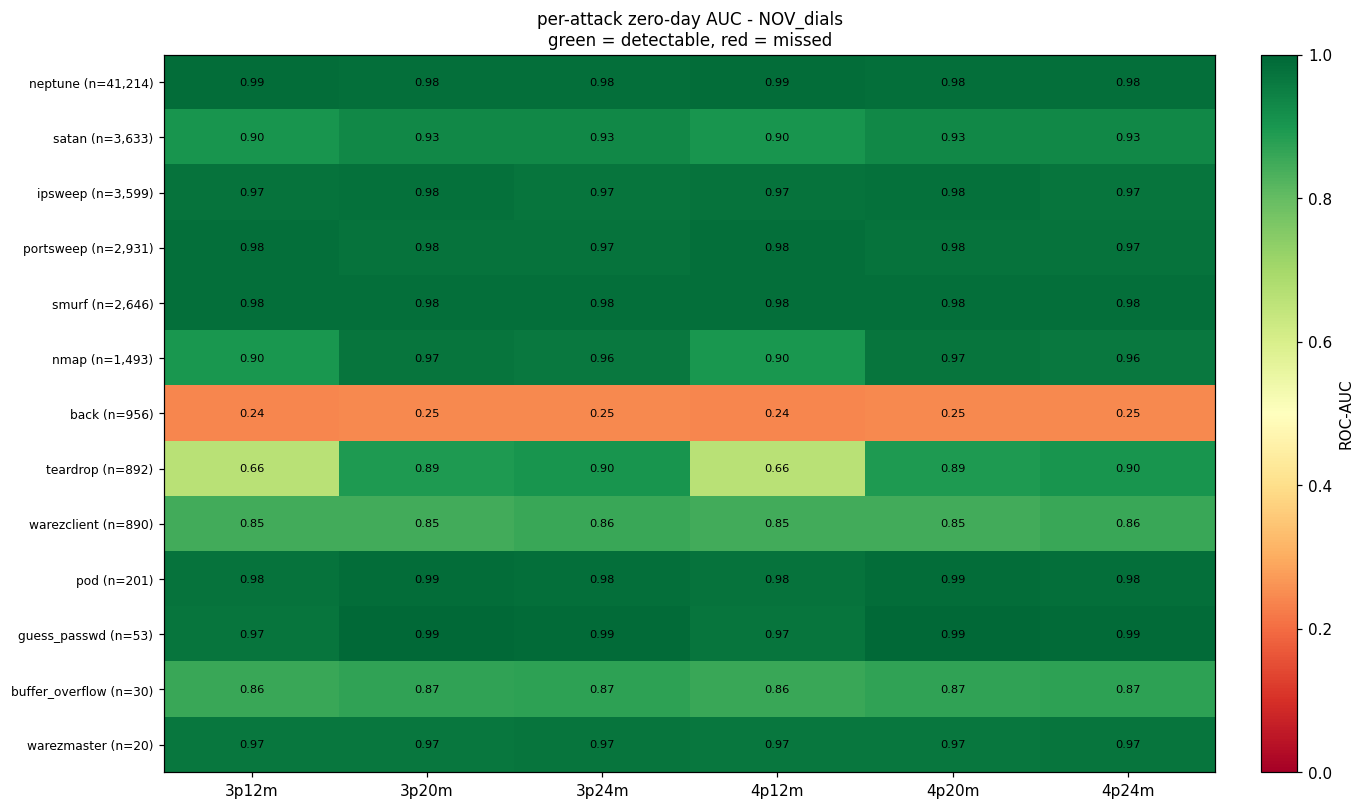

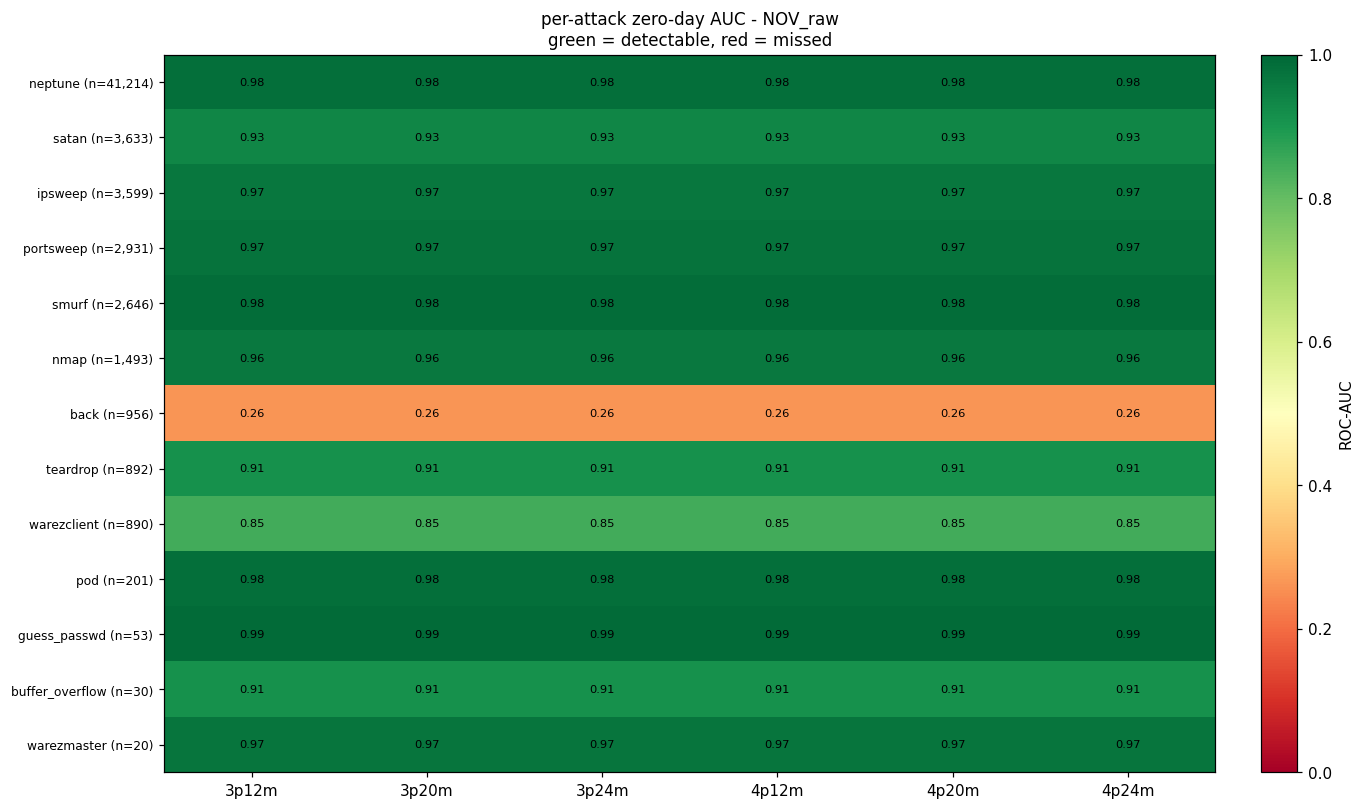

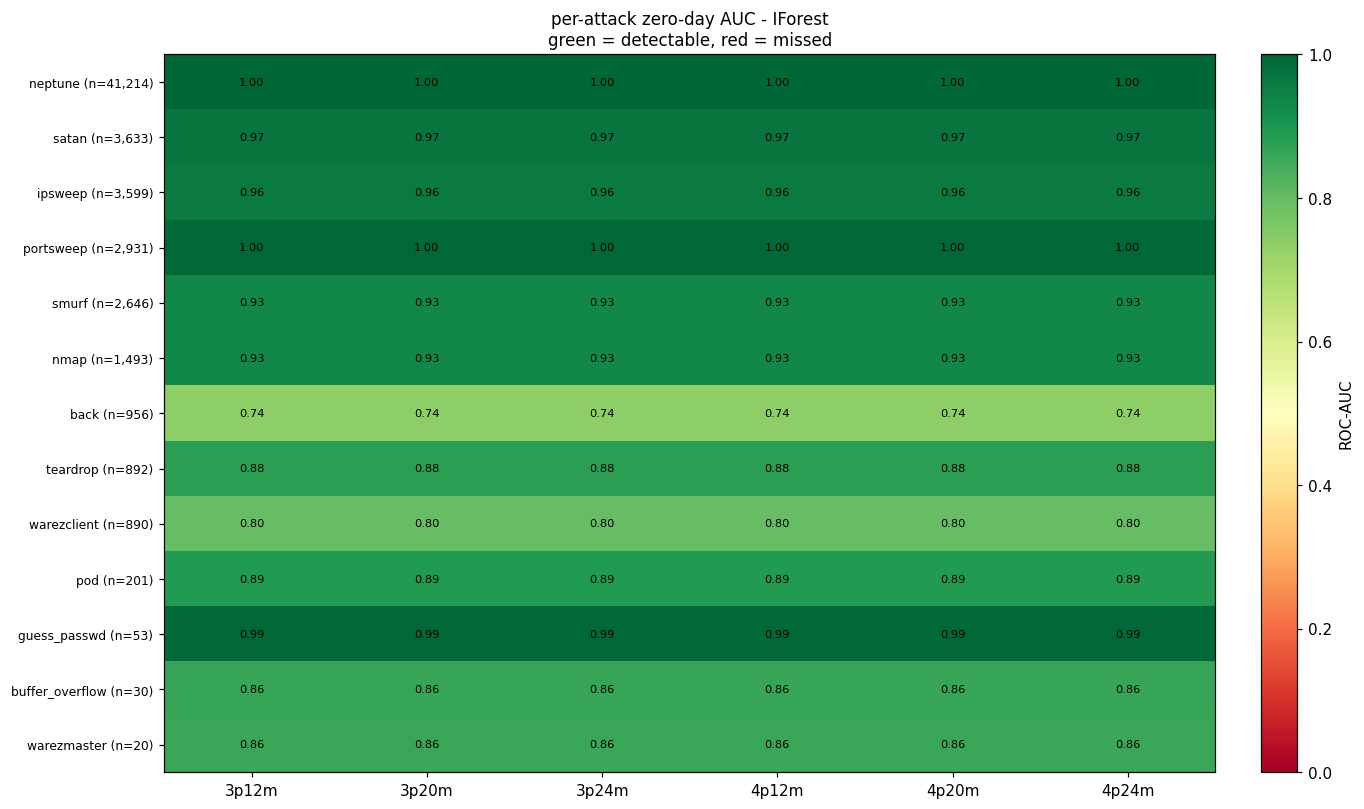

In [13]:
# Heatmap: per-attack AUC across configs, for each detector
for det in DETECTORS:
    keep = [a for a in ATTACKS if ATTACK_N[a] >= MIN_SUPPORT]
    M = np.zeros((len(keep), len(cfgs)))
    for j, cfg in enumerate(cfgs):
        pa = by_cfg[cfg]["detectors"][det]["per_attack"]
        for i, a in enumerate(keep):
            M[i, j] = pa[a]["auc"]
    fig, ax = plt.subplots(figsize=(1.5*len(cfgs)+3.5, 0.42*len(keep)+2))
    im = ax.imshow(M, cmap="RdYlGn", vmin=0, vmax=1, aspect="auto")
    ax.set_xticks(range(len(cfgs))); ax.set_xticklabels(cfgs)
    ax.set_yticks(range(len(keep)))
    ax.set_yticklabels([f"{a} (n={ATTACK_N[a]:,})" for a in keep], fontsize=8)
    for i in range(M.shape[0]):
        for j in range(M.shape[1]):
            ax.text(j, i, f"{M[i,j]:.2f}", ha="center", va="center", fontsize=7.5)
    ax.set_title(f"per-attack zero-day AUC - {det}\ngreen = detectable, red = missed",
                 fontsize=11)
    fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04, label="ROC-AUC")
    plt.tight_layout(); plt.show()

### 8.5 Operational view — detection rate at a fixed false-alarm budget

AUC is threshold-free, which makes it a poor proxy for deployment: a security
team must fix a threshold **before** seeing the attack. These numbers set the
threshold on normal traffic alone (allowing 0.1% / 1% / 5% false alarms) and
report what fraction of each attack is caught.

At 67,343 normal rows, a 1% false-alarm rate is roughly 670 alerts to triage —
already a lot. 0.1% is the realistic regime for a busy network.

In [14]:
op = []
for cfg in cfgs:
    for det in DETECTORS:
        h = by_cfg[cfg]["detectors"][det]
        row = {"config": cfg, "detector": det, "auc_all": h["auc_all"],
               "auc_macro_big": h["auc_macro_big"]}
        row.update({f"det@{fa:g}%FA": h["det_at_fa"][str(fa)] for fa in FA_BUDGETS})
        op.append(row)
OP = pd.DataFrame(op)
OP["config"] = pd.Categorical(OP["config"], CONFIG_ORDER, ordered=True)
OP = OP.sort_values(["config", "detector"])
print("===== detection rate at fixed false-alarm budgets (all attacks pooled) =====")
print(OP.round(4).to_string(index=False))

# per-attack detection at the strictest budget
strict = min(FA_BUDGETS)
tbl3 = {}
for cfg in cfgs:
    pa = by_cfg[cfg]["detectors"]["NOV_q"]["per_attack"]
    tbl3[cfg] = {a: pa[a]["det_at_fa"][str(strict)] for a in ATTACKS if a in pa}
T3 = pd.DataFrame(tbl3)
T3.insert(0, "n", [ATTACK_N[a] for a in T3.index])
print(f"\n===== per-attack detection rate at {strict:g} false-alarm budget - NOV_q =====")
print(T3.round(3).to_string())

===== detection rate at fixed false-alarm budgets (all attacks pooled) =====
config  detector  auc_all  auc_macro_big  det@0.001%FA  det@0.01%FA  det@0.05%FA
 3p12m   IForest   0.9798         0.9074        0.4060       0.7975       0.8863
 3p12m NOV_dials   0.9581         0.8653        0.0006       0.6335       0.8104
 3p12m     NOV_q   0.9698         0.9120        0.0504       0.2327       0.9191
 3p12m   NOV_raw   0.9616         0.8985        0.0229       0.2999       0.8169
 3p20m   IForest   0.9798         0.9074        0.4060       0.7975       0.8863
 3p20m NOV_dials   0.9640         0.8939        0.0064       0.6224       0.8238
 3p20m     NOV_q   0.9520         0.9067        0.0018       0.0649       0.6364
 3p20m   NOV_raw   0.9616         0.8985        0.0229       0.2999       0.8169
 3p24m   IForest   0.9798         0.9074        0.4060       0.7975       0.8863
 3p24m NOV_dials   0.9614         0.8946        0.0136       0.4036       0.8172
 3p24m     NOV_q   0.9503       

### 8.6 Score distributions — normal vs attack

The picture behind the AUC. A clean right-shift means the attack is genuinely
anomalous under this detector; heavy overlap is the honest limitation.

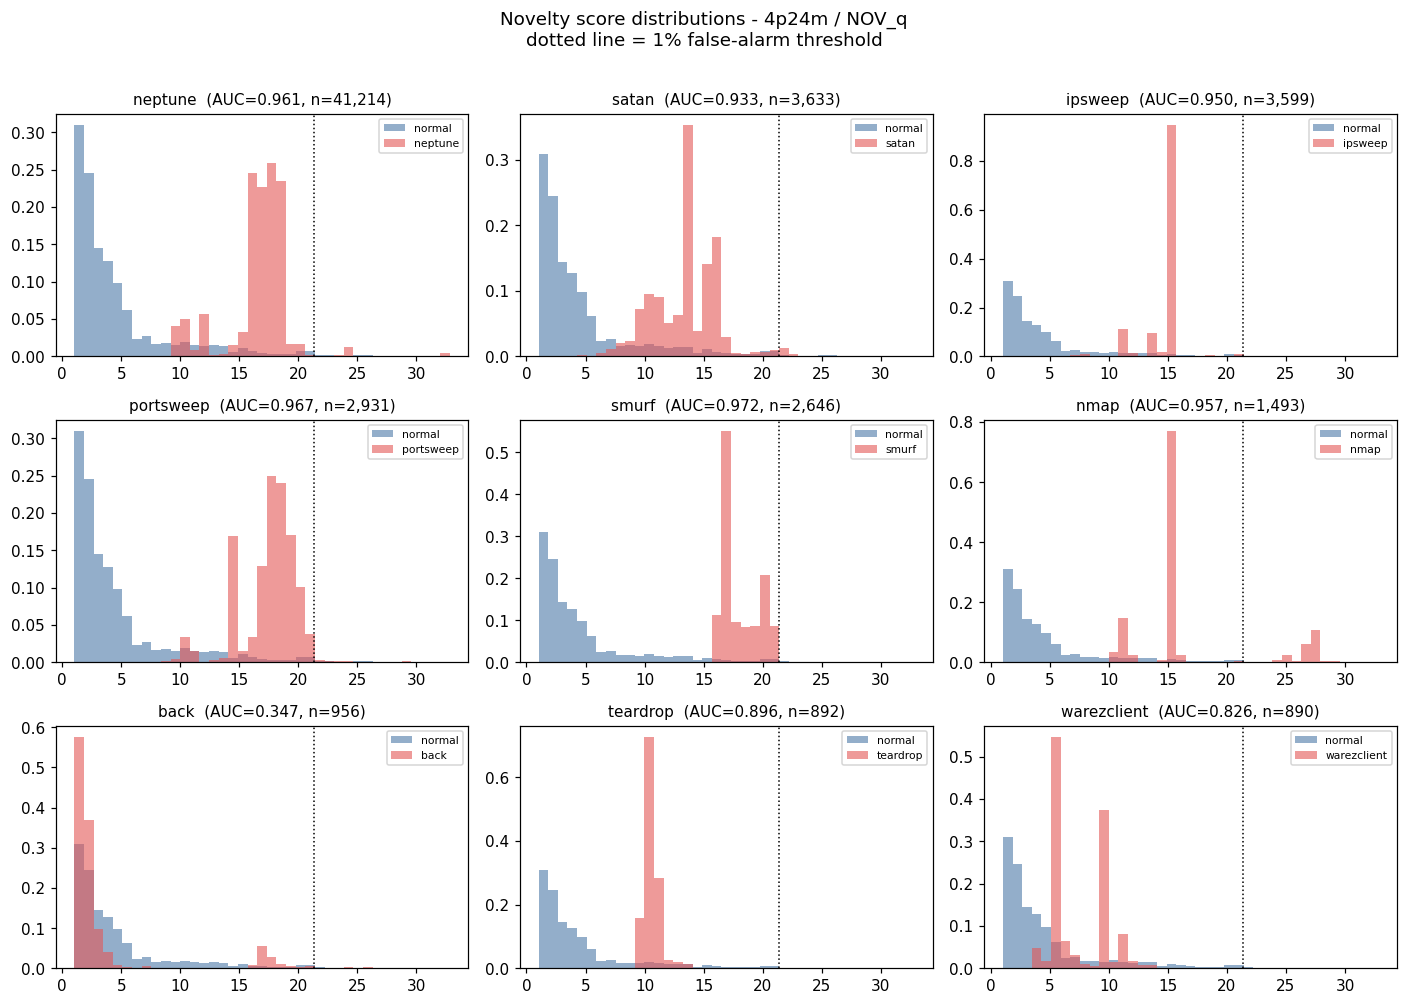

In [15]:
SHOW_CFG = cfgs[-1] if cfgs else None
SHOW_DET = "NOV_q"

f = art / f"scores_{SHOW_CFG}_{SHOW_DET}.npz"
if SHOW_CFG and f.exists():
    z = np.load(f)
    s_norm, s_atk = z["s_norm"], z["s_atk"]
    atk_of_row = attack_type[attack_idx]

    show = [a for a in ATTACKS if ATTACK_N[a] >= 200][:9]
    ncol = 3; nrow = int(np.ceil(len(show)/ncol))
    fig, axes = plt.subplots(nrow, ncol, figsize=(4.3*ncol, 3.0*nrow))
    axes = np.array(axes).reshape(-1)
    hi_global = np.quantile(np.r_[s_norm, s_atk], 0.995)
    for ax, a in zip(axes, show):
        sa = s_atk[atk_of_row == a]
        lo = min(s_norm.min(), sa.min())
        bins = np.linspace(lo, hi_global, 40)
        ax.hist(s_norm, bins=bins, alpha=0.6, density=True,
                color="#4C78A8", label="normal")
        ax.hist(sa, bins=bins, alpha=0.6, density=True,
                color="#E45756", label=a)
        auc_a = by_cfg[SHOW_CFG]["detectors"][SHOW_DET]["per_attack"][a]["auc"]
        ax.axvline(np.quantile(s_norm, 0.99), color="k", ls=":", lw=1)
        ax.set_title(f"{a}  (AUC={auc_a:.3f}, n={ATTACK_N[a]:,})", fontsize=10)
        ax.legend(fontsize=7)
    for ax in axes[len(show):]:
        ax.axis("off")
    fig.suptitle(f"Novelty score distributions - {SHOW_CFG} / {SHOW_DET}\n"
                 f"dotted line = 1% false-alarm threshold", y=1.01)
    plt.tight_layout(); plt.show()
else:
    print(f"score artifact not found: {f}")

### 8.7 ROC curves — per attack, and per config

Left: how each attack type separates under the best config. Right: whether
reservoir capacity moves the curve at all, pooled over every attack.

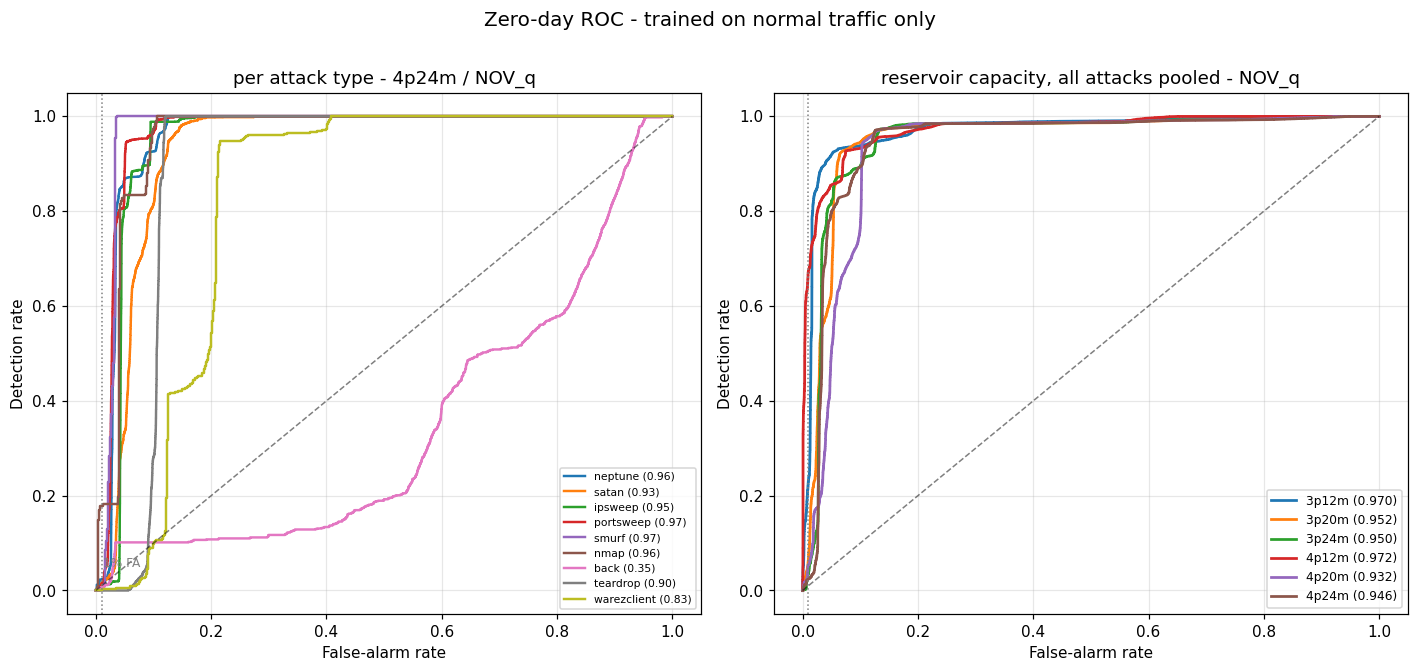

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(13, 6))

# --- left: per attack, at SHOW_CFG
f = art / f"scores_{SHOW_CFG}_{SHOW_DET}.npz"
if SHOW_CFG and f.exists():
    z = np.load(f); s_norm, s_atk = z["s_norm"], z["s_atk"]
    atk_of_row = attack_type[attack_idx]
    for a in [x for x in ATTACKS if ATTACK_N[x] >= 200][:9]:
        sa = s_atk[atk_of_row == a]
        y = np.r_[np.zeros(len(s_norm)), np.ones(len(sa))]
        fpr, tpr, _ = roc_curve(y, np.r_[s_norm, sa])
        au = by_cfg[SHOW_CFG]["detectors"][SHOW_DET]["per_attack"][a]["auc"]
        axes[0].plot(fpr, tpr, lw=1.6, label=f"{a} ({au:.2f})")
    axes[0].plot([0, 1], [0, 1], "k--", lw=1, alpha=.5)
    axes[0].axvline(0.01, color="gray", ls=":", lw=1)
    axes[0].text(0.012, 0.05, "1% FA", color="gray", fontsize=8)
    axes[0].set_title(f"per attack type - {SHOW_CFG} / {SHOW_DET}")
    axes[0].legend(fontsize=7, loc="lower right")

# --- right: per config, all attacks pooled
for cfg in cfgs:
    f = art / f"scores_{cfg}_{SHOW_DET}.npz"
    if not f.exists():
        continue
    z = np.load(f); s_norm, s_atk = z["s_norm"], z["s_atk"]
    y = np.r_[np.zeros(len(s_norm)), np.ones(len(s_atk))]
    fpr, tpr, _ = roc_curve(y, np.r_[s_norm, s_atk])
    au = by_cfg[cfg]["detectors"][SHOW_DET]["auc_all"]
    axes[1].plot(fpr, tpr, lw=1.8, label=f"{cfg} ({au:.3f})")
axes[1].plot([0, 1], [0, 1], "k--", lw=1, alpha=.5)
axes[1].axvline(0.01, color="gray", ls=":", lw=1)
axes[1].set_title(f"reservoir capacity, all attacks pooled - {SHOW_DET}")
axes[1].legend(fontsize=8, loc="lower right")

for ax in axes:
    ax.set_xlabel("False-alarm rate"); ax.set_ylabel("Detection rate")
    ax.grid(alpha=0.3)
fig.suptitle("Zero-day ROC - trained on normal traffic only", y=1.01, fontsize=13)
plt.tight_layout(); plt.show()

### 8.8 Cost — is the biggest reservoir worth what it costs?

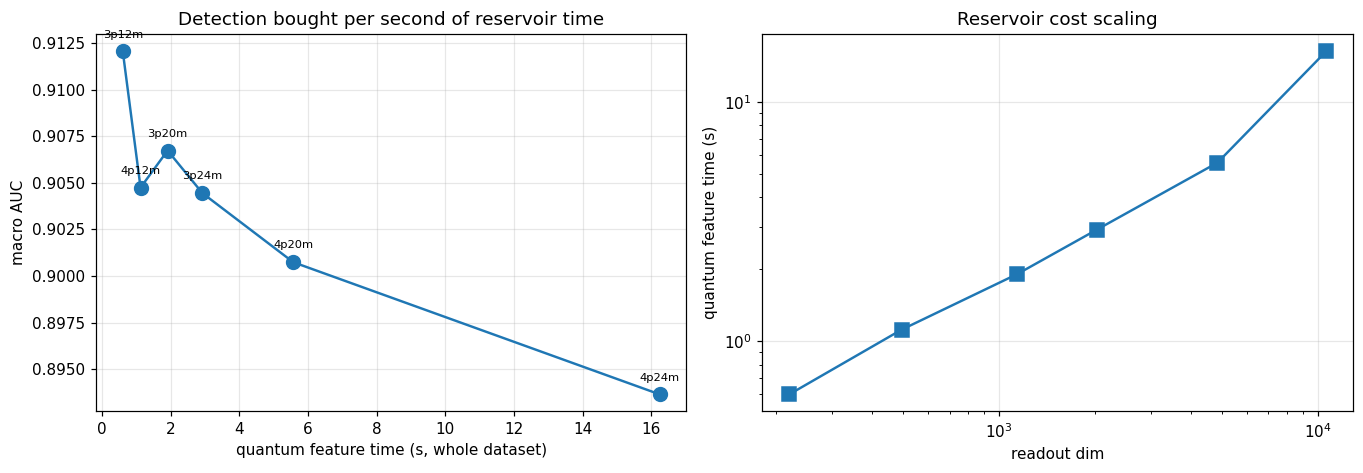

In [17]:
cost = D[D["detector"] == "NOV_q"].sort_values("readout_dim")
fig, ax = plt.subplots(1, 2, figsize=(12.5, 4.4))
ax[0].plot(cost["t_quantum_s"], cost["auc_macro_big"], marker="o", ms=9, lw=1.6)
for _, r in cost.iterrows():
    ax[0].annotate(r["config"], (r["t_quantum_s"], r["auc_macro_big"]),
                   textcoords="offset points", xytext=(0, 9), ha="center", fontsize=7.5)
ax[0].set_xlabel("quantum feature time (s, whole dataset)")
ax[0].set_ylabel("macro AUC")
ax[0].set_title("Detection bought per second of reservoir time")

ax[1].plot(cost["readout_dim"], cost["t_quantum_s"], marker="s", ms=9, lw=1.6)
ax[1].set_xlabel("readout dim"); ax[1].set_ylabel("quantum feature time (s)")
ax[1].set_xscale("log"); ax[1].set_yscale("log")
ax[1].set_title("Reservoir cost scaling")
for a in ax:
    a.grid(alpha=0.3)
plt.tight_layout(); plt.show()

## 9. Summary — what the sweep concluded

Auto-generated from the results so the written claim always matches the numbers
on disk. Read the caveats: they are the difference between an honest result and
an overclaim.

In [18]:
lines = ["", "=" * 72, "ZERO-DAY NOVELTY SUMMARY", "=" * 72,
         f"protocol: trained on {len(tr_idx):,} NORMAL rows only; scored against",
         f"          {len(attack_idx):,} attack rows across {len(ATTACKS)} types,",
         f"          every one of them unseen during training.",
         ""]

best = D.loc[D.groupby("detector", observed=True)["auc_macro_big"].idxmax()]
lines.append("--- best config per detector (macro AUC over attack types) ---")
for _, r in best.iterrows():
    lines.append(f"  {r['detector']:10s} {r['config']:6s} (dim {int(r['input_dim']):5d}) "
                 f"macro_AUC={r['auc_macro_big']:.4f}  pooled_AUC={r['auc_all']:.4f}  "
                 f"det@1%FA={r['det@0.01']:.4f}")

bq = D[D["detector"] == "NOV_q"].nlargest(1, "auc_macro_big")
bd = D[D["detector"] == "NOV_dials"].nlargest(1, "auc_macro_big")
if len(bq) and len(bd):
    delta = bq.iloc[0]["auc_macro_big"] - bd.iloc[0]["auc_macro_big"]
    verdict = ("reservoir ahead of its own input" if delta > 0.01 else
               "reservoir behind its own input"   if delta < -0.01 else
               "reservoir indistinguishable from its own input")
    lines += ["", f"best-vs-best (NOV_q - NOV_dials) macro AUC delta = {delta:+.4f}",
              f"  -> {verdict}"]

gains = []
for cfg in cfgs:
    s = D[D["config"] == cfg]
    q = s[s["detector"] == "NOV_q"]; d = s[s["detector"] == "NOV_dials"]
    if len(q) and len(d):
        gains.append((cfg, q.iloc[0]["auc_macro_big"] - d.iloc[0]["auc_macro_big"]))
if gains:
    pos = sum(1 for _, g in gains if g > 0)
    lines.append(f"per-config gain: {pos}/{len(gains)} configs favour quantum  "
                 + " ".join(f"[{c}:{g:+.3f}]" for c, g in gains))
    qs = D[D["detector"] == "NOV_q"].sort_values("readout_dim")
    if len(qs) >= 2:
        trend = qs.iloc[-1]["auc_macro_big"] - qs.iloc[0]["auc_macro_big"]
        lines.append(f"capacity trend (smallest -> largest reservoir): "
                     f"{trend:+.4f} macro AUC")

# which attacks are simply not catchable by any detector at any config
lines += ["", "--- per-attack verdict (best over all configs/detectors) ---"]
for a in ATTACKS:
    best_a = max((by_cfg[c]["detectors"][d]["per_attack"][a]["auc"]
                  for c in cfgs for d in DETECTORS), default=None)
    if best_a is None:
        continue
    mark = ("detectable" if best_a >= 0.80 else
            "marginal"   if best_a >= 0.65 else
            "MISSED")
    small = "" if ATTACK_N[a] >= MIN_SUPPORT else "  (n too small to trust)"
    lines.append(f"  {a:<18s} n={ATTACK_N[a]:>6,d}  best AUC={best_a:.3f}  {mark}{small}")

lines += ["", "-" * 72, "CAVEATS", "-" * 72,
          "* Single seed (42). The reservoir unitary and the normal split are both",
          "  random; the original zero-day notebook saw std up to 0.17 across seeds",
          "  on one arm. A capacity trend smaller than that is NOT established.",
          "  Rerun with 2-3 seeds before claiming one.",
          "* Pooled AUC is dominated by neptune (41,214 of 58,630 attack rows).",
          "  Quote auc_macro_big, which weights attack TYPES equally.",
          f"* Attack types with fewer than {MIN_SUPPORT} rows are reported but excluded",
          "  from aggregates; with n=2 an AUC is one row's luck, not a measurement.",
          "* AUC is threshold-free and flatters a detector that would be useless in",
          "  practice. The det@FA columns are the deployable numbers.",
          "* NSL-KDD attacks are not real zero-days -- they are known attacks the",
          "  detector was not shown. That is the right experiment for this question,",
          "  but it does not prove performance against genuinely novel traffic.",
          "* The NOV_dials control shares the reservoir's own PCA front-end, so any",
          "  gain over it is attributable to the reservoir rather than preprocessing."]

summary = "\n".join(lines)
print(summary)
(Path(INSPECT_PATH).parent / "summary.txt").write_text(summary, encoding="utf-8")
print(f"\n(saved to {Path(INSPECT_PATH).parent / 'summary.txt'})")


ZERO-DAY NOVELTY SUMMARY
protocol: trained on 47,140 NORMAL rows only; scored against
          58,630 attack rows across 22 types,
          every one of them unseen during training.

--- best config per detector (macro AUC over attack types) ---
  IForest    3p12m  (dim   122) macro_AUC=0.9074  pooled_AUC=0.9798  det@1%FA=0.7975
  NOV_dials  3p24m  (dim    24) macro_AUC=0.8946  pooled_AUC=0.9614  det@1%FA=0.4036
  NOV_q      3p12m  (dim   220) macro_AUC=0.9120  pooled_AUC=0.9698  det@1%FA=0.2327
  NOV_raw    3p12m  (dim   122) macro_AUC=0.8985  pooled_AUC=0.9616  det@1%FA=0.2999

best-vs-best (NOV_q - NOV_dials) macro AUC delta = +0.0175
  -> reservoir ahead of its own input
per-config gain: 5/6 configs favour quantum  [3p12m:+0.047] [3p20m:+0.013] [3p24m:+0.010] [4p12m:+0.039] [4p20m:+0.007] [4p24m:-0.001]
capacity trend (smallest -> largest reservoir): -0.0184 macro AUC

--- per-attack verdict (best over all configs/detectors) ---
  neptune            n=41,214  best AUC=0.999  det

### 8.9 Pitch figure — attack detection accuracy

The deck version of the capacity question. Same numbers as 8.2, but scored the
way a slide audience reads a detector: **accuracy at the best achievable
threshold**, not AUC. Bars are grouped by mode count so 3 vs 4 photons sit side
by side, and the dashed line is the strongest classical control on the identical
task (`NOV_raw`, all 122 features) — the honest comparison, since it sees the
same rows the reservoir does.

Writes `pitch_figures/11_novelty_accuracy.png`. This is the same figure
`qorc_pitch_figures.ipynb` produces; it lives here too so the sweep is
self-contained and the figure can never drift from the run that made it.


In [ ]:
# --------------------------------------------------------------- pitch style
# Self-contained: this cell only needs `art` and `cfgs` from cell 8.
import matplotlib as mpl
from matplotlib.ticker import PercentFormatter

PINK      = "#6D28E0"     # quantum -- the hero colour (violet)
PINK_SOFT = "#A97CF0"     # quantum, secondary series
DIM_DARK  = "#8A8A8A"     # classical reference -- deliberately quiet
INK       = "#3C3C46"
GRID      = "#EAEAF2"

PITCH_RC = {
    "figure.dpi": 120, "savefig.dpi": 300,
    "savefig.bbox": "tight", "savefig.facecolor": "white",
    "font.size": 11, "axes.titlesize": 13, "axes.titleweight": "bold",
    "axes.labelsize": 11, "axes.edgecolor": "#CCCCCC",
    "axes.labelcolor": INK, "text.color": INK,
    "xtick.color": INK, "ytick.color": INK,
    "axes.spines.top": False, "axes.spines.right": False,
    "grid.color": GRID, "legend.frameon": False,
}

FIGDIR = Path("pitch_figures")
FIGDIR.mkdir(exist_ok=True)

def save_pitch(fig, name):
    p = FIGDIR / f"{name}.png"
    fig.savefig(p)
    print(f"  saved {p}")
    return p

# ------------------------------------------------------------- accuracy calc
def best_accuracy(s_norm, s_atk, n_grid=400):
    """Accuracy at the threshold that maximises it, plus that operating point.

    The novelty head never sees an attack during training, so it has no way to
    pick a threshold from data. Reporting the best achievable accuracy answers
    "how separable are these scores at all", which is what the slide claims.
    """
    y = np.r_[np.zeros(len(s_norm)), np.ones(len(s_atk))]
    s = np.r_[s_norm, s_atk]
    grid = np.quantile(s, np.linspace(0.005, 0.995, n_grid))
    accs = np.array([(((s > t).astype(int)) == y).mean() for t in grid])
    i = int(accs.argmax())
    t = grid[i]
    return float(accs[i]), float((s_atk > t).mean()), float((s_norm > t).mean())

nov_acc = {det: {} for det in DETECTORS}
for c in cfgs:
    for det in DETECTORS:
        f = art / f"scores_{c}_{det}.npz"
        if not f.exists():
            continue
        z = np.load(f)
        nov_acc[det][c] = best_accuracy(z["s_norm"].astype(float),
                                        z["s_atk"].astype(float))[0]

# attack base rate -- what "guess everything is an attack" would score
rec0 = rows[0]
BASE_RATE = rec0["n_attack"] / (rec0["n_attack"] + rec0["n_score_normal"])
print(f"attack base rate (trivial all-attack guess): {BASE_RATE:.4f}")
print(pd.DataFrame({d: pd.Series(nov_acc[d]) for d in DETECTORS}
                   ).reindex(cfgs).round(4).to_string())

# ------------------------------------------------------------------ grouping
# One group per mode count; within each group, 3 photons vs 4 photons.
MODES    = sorted({int(c.split("p")[1].rstrip("m")) for c in cfgs})
PHOTONS  = sorted({int(c.split("p")[0]) for c in cfgs})
PH_COLOR = {3: PINK_SOFT, 4: PINK}        # 4 photons = the deeper violet
gx       = np.arange(len(MODES))
GW       = 0.34                            # bar width within a group

def draw_groups(ax, lookup, fmt="{:.1f}%", scale=100, fontsize=11):
    """Grouped bars + value labels. Returns the flat list of plotted values."""
    vals = []
    for k, p in enumerate(PHOTONS):
        v = [lookup.get(f"{p}p{m}m", np.nan) for m in MODES]
        vals += [q for q in v if np.isfinite(q)]
        off = (k - (len(PHOTONS) - 1) / 2) * GW
        ax.bar(gx + off, v, GW, color=PH_COLOR.get(p, PINK), zorder=3,
               label=f"{p} photons")
        for xi, q in zip(gx + off, v):
            if np.isfinite(q):
                ax.annotate(fmt.format(q * scale), (xi, q),
                            textcoords="offset points", xytext=(0, 6),
                            ha="center", fontsize=fontsize,
                            fontweight="bold", color=INK, zorder=5)
    ax.set_xticks(gx)
    ax.set_xticklabels([f"{m} modes\n{math.comb(m, 3):,} / {math.comb(m, 4):,} Fock states"
                        for m in MODES], fontsize=9)
    return vals

with mpl.rc_context(PITCH_RC):
    fig, ax = plt.subplots(figsize=(8.6, 5.6))
    vals = draw_groups(ax, nov_acc["NOV_q"])

    # single dim reference: the strongest classical detector on the same task
    ref = max(nov_acc["NOV_raw"].values())
    ax.axhline(ref, color=DIM_DARK, lw=1.6, ls="--", zorder=2)
    ax.annotate(f"Classical detector \u2248 {ref*100:.1f}%",
                xy=(gx[-1] + 0.42, ref), xytext=(0, 6),
                textcoords="offset points", ha="right", va="bottom",
                fontsize=8.5, color=DIM_DARK)

    lo, hi = min(vals + [ref]), max(vals + [ref])
    pad = (hi - lo) * 0.32
    ax.set_ylim(lo - pad, hi + pad)
    ax.text(0.0, 1.02, "accuracy  (best achievable)", transform=ax.transAxes,
            fontsize=10, color=INK, ha="left", va="bottom")
    ax.yaxis.set_major_formatter(PercentFormatter(1.0))
    ax.set_xlim(gx[0] - 0.55, gx[-1] + 0.55)
    ax.set_title("Attack detection accuracy", pad=26, fontsize=12.5)
    ax.grid(axis="y", alpha=0.55); ax.set_axisbelow(True)
    ax.legend(loc="upper left", fontsize=9.5, ncol=2)

    plt.tight_layout(); save_pitch(fig, "11_novelty_accuracy"); plt.show()


### 9.1 Export tables for the write-up

In [19]:
outdir = Path(INSPECT_PATH).parent
D.to_csv(outdir / "metrics_flat.csv", index=False)

pa_rows = []
for r in rows:
    for det in DETECTORS:
        if det not in r["detectors"]:
            continue
        for a, m in r["detectors"][det]["per_attack"].items():
            pa_rows.append({"config": r["config"], "detector": det,
                            "readout_dim": r["readout_dim"], "attack": a,
                            "n": m["n"], "auc": m["auc"],
                            **{f"det@{fa}": m["det_at_fa"][str(fa)] for fa in FA_BUDGETS}})
pd.DataFrame(pa_rows).to_csv(outdir / "metrics_per_attack.csv", index=False)

if "OP" in dir() and len(OP):
    OP.to_csv(outdir / "metrics_operational.csv", index=False)

print("written:")
for f in sorted(outdir.glob("*.csv")):
    print(f"  {f}  ({f.stat().st_size/1024:.1f} KB)")
print(f"  {outdir/'summary.txt'}")
print(f"  {outdir/'run.log'}")

written:
  qorc_nov_runs\20260810_210640\metrics_flat.csv  (4.4 KB)
  qorc_nov_runs\20260810_210640\metrics_operational.csv  (2.7 KB)
  qorc_nov_runs\20260810_210640\metrics_per_attack.csv  (43.2 KB)
  qorc_nov_runs\20260810_210640\summary.txt
  qorc_nov_runs\20260810_210640\run.log
